# Diverging, cyclic and categorical schemes, each in use

**Shows:** the named schemes that are not dark-to-light ramps. Top row: every scheme of each kind as a strip.
Bottom row: a diverging scheme on a signed field, a cyclic scheme on an angle, and a categorical scheme
as the colours of a set of lines.

**Graph types:** swatch chart (`lf.swatches`), heat maps (`lf.heatmap`), line series.

**Writes:** `schemes.svg` next to this notebook.

**To tweak:** change the capitalised settings at the top of the **Figure** cell and re-run that cell.
The figure sets its own style with `lf.use`, because the series colours are one of the settings.

**Runs on:** the default `python3` kernel: Python 3.10 or newer with labfigs installed.

**To run it all:** `jupyter nbconvert --to notebook --execute --inplace schemes.ipynb`, which also saves the figures in this notebook.

In [1]:
import numpy as np

import labfigs as lf

## Data

- `kinds`: `{kind: {scheme name: colours}}` for the top row, read from the library
- `xx`, `yy`: grids of the two coordinates, shape `(80, 80)`
- `signed_field`: values on both sides of zero, for the diverging scheme
- `angle_field`: an angle between -pi and pi, for the cyclic scheme
- `x`: positions of the line series, length 200

In [2]:
kinds = {kind: lf.combos(kind=kind) for kind in lf.KINDS}
xx, yy = np.meshgrid(np.linspace(0, 1, 80), np.linspace(0, 1, 80))
signed_field = 0.08 * np.sin(5 * xx) * np.cos(4 * yy)
angle_field = np.arctan2(yy - 0.5, xx - 0.5)
x = np.linspace(0, 1, 200)

## Figure

Settings at the top of the cell:

- `NAME`: file name of the figure, without `.svg`
- `WIDTH`, `PANEL_ASPECT`: figure width in inches, and the height of one panel divided by its width
- `SERIES`: categorical scheme used for the lines; any scheme name in the Categorical strip
- `SIGNED_RAMP`: diverging scheme of the signed field; its middle colour sits at zero
- `CYCLIC_RAMP`: cyclic scheme of the angle; its two ends are the same colour
- `FIELD_TICKS`, `X_LABEL`, `Y_LABEL`: axes of the two heat maps
- `LINE_TICKS`, `LINE_Y_LABEL`: y axis of the line panel

PosixPath('schemes.svg')

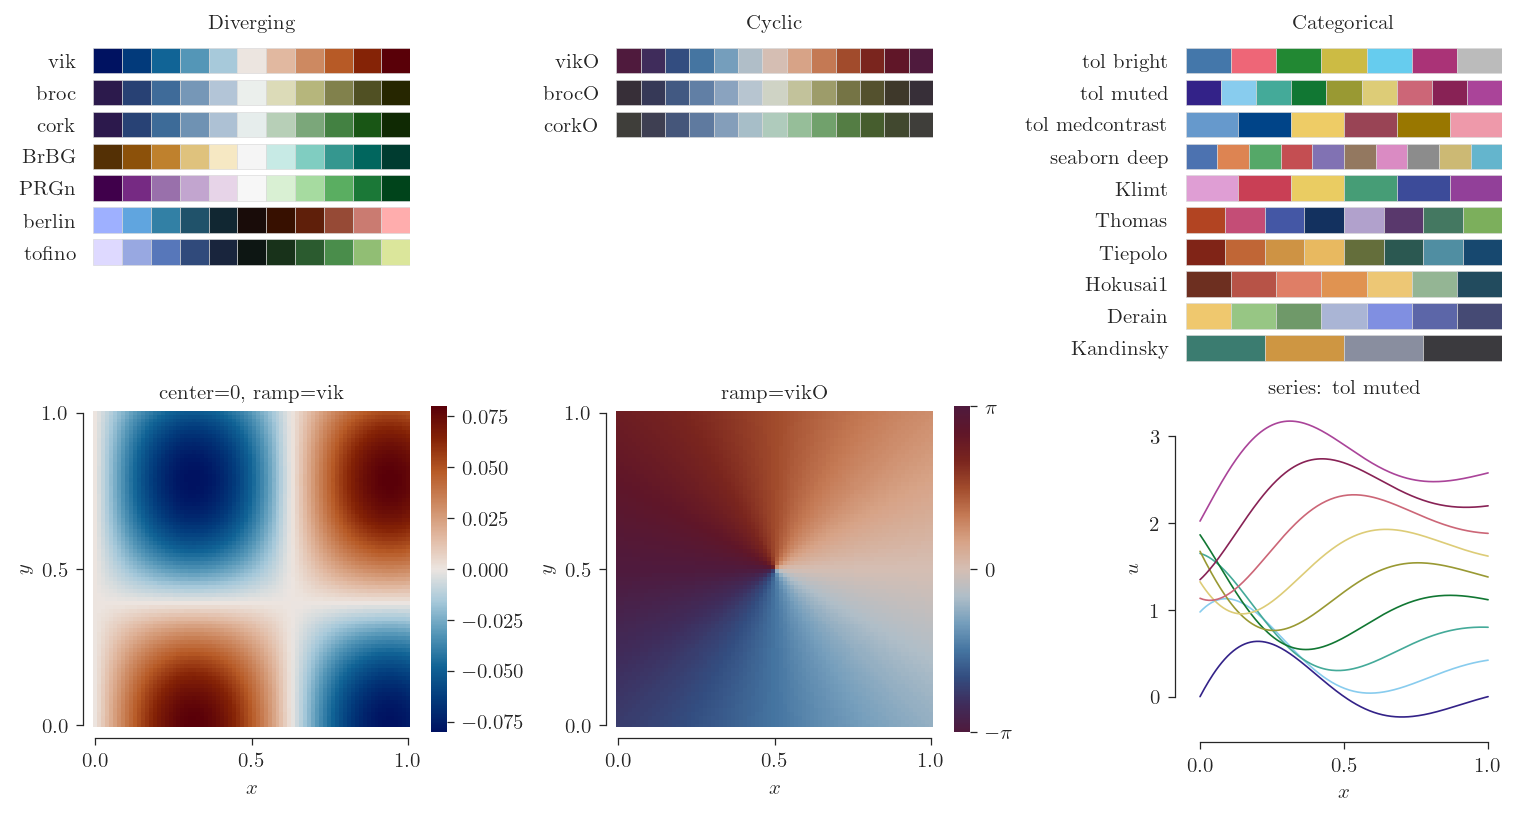

In [3]:
NAME = "schemes"
WIDTH, PANEL_ASPECT = 10, 0.8
SERIES = "tol_muted"
SIGNED_RAMP, CYCLIC_RAMP = "vik", "vikO"
FIELD_TICKS, X_LABEL, Y_LABEL = [0, 0.5, 1], "$x$", "$y$"
LINE_TICKS, LINE_Y_LABEL = [0, 1, 2, 3], "$u$"

lf.use(series=SERIES)
fig, (top, bottom) = lf.subplots(2, 3, width=WIDTH, aspect=PANEL_ASPECT)
for ax, (kind, sets) in zip(top, kinds.items()):
    lf.swatches(ax, sets)
    ax.set(title=kind.capitalize(), ylim=(max(map(len, kinds.values())) - 0.4, -0.6))

signed, phase, lines = bottom
lf.heatmap(signed, xx, yy, signed_field, ramp=SIGNED_RAMP, center=0)
turn = lf.heatmap(phase, xx, yy, angle_field, ramp=CYCLIC_RAMP, vmin=-np.pi, vmax=np.pi)
turn.colorbar.set_ticks([-np.pi, 0, np.pi], labels=[r"$-\pi$", "0", r"$\pi$"])
for ax, title in ((signed, f"center=0, ramp={SIGNED_RAMP}"), (phase, f"ramp={CYCLIC_RAMP}")):
    ax.set(title=title, xticks=FIELD_TICKS, yticks=FIELD_TICKS, xlabel=X_LABEL, ylabel=Y_LABEL, aspect="equal")
for shift in range(len(lf.COMBOS[SERIES])):
    lines.plot(x, np.exp(-2 * x) * np.sin(2 * np.pi * (x + shift / 9)) + shift / 3)
lines.set(title=f"series: {SERIES.replace('_', ' ')}", xticks=FIELD_TICKS, yticks=LINE_TICKS, xlabel=X_LABEL, ylabel=LINE_Y_LABEL)
lf.save(fig, NAME)

## Checks

Fails if a scheme is filed under two kinds, is too vivid, or does not behave as its kind promises:
cyclic schemes end where they start, diverging schemes have their lightest or darkest colour in the
middle, categorical schemes span more than half the colour wheel. Nothing to tweak.

In [4]:
named = [key for key in lf.COMBOS if isinstance(key, str)]
assert sum(map(len, lf.KINDS.values())) == len({key for names in lf.KINDS.values() for key in names}) < len(named)
assert all(lf.vividness(colours) <= 0.6 for sets in kinds.values() for colours in sets.values())
assert all(colours[0] == colours[-1] for colours in kinds["cyclic"].values())
for colours in kinds["diverging"].values():
    shade = [lf.luma(colour) for colour in colours]
    assert shade.index(max(shade)) == 5 or shade.index(min(shade)) == 5, colours
assert all(lf.hue_arc(colours) > 180 for colours in kinds["categorical"].values()) and lf.kind_of("devon") == "sequential"
assert signed.collections[0].cmap.name == SIGNED_RAMP and lf.kind_of(120) == "combination" and len(lf.combos(kind="sequential")) > 40